MHW会议后，增加SSHA图

In [1]:
file=r"D:\data\model\Global Ocean Gridded L 4 Sea Surface Heights\cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.25deg_P1M-m_1697447293140.nc"

In [2]:
import numpy as np                   
import xarray as xr  
import matplotlib.pyplot as plt  
import sacpy as scp                  

In [3]:
ssha=xr.open_dataset(file)
ssha=ssha.sla

In [4]:
ssha

<xarray.DataArray 'sla' (time: 355, latitude: 161, longitude: 361)>
[20632955 values with dtype=float64]
Coordinates:
  * latitude   (latitude) float32 -59.88 -59.62 -59.38 ... -20.38 -20.12 -19.88
  * time       (time) datetime64[ns] 1993-01-15 1993-02-15 ... 2022-07-15
  * longitude  (longitude) float32 139.9 140.1 140.4 140.6 ... 229.4 229.6 229.9
Attributes:
    cell_methods:   time: mean within years
    grid_mapping:   crs
    long_name:      Averaged Sea Level Anomalies 2022/07
    standard_name:  sea_surface_height_above_sea_level
    units:          m
    _ChunkSizes:    [ 1 50 50]

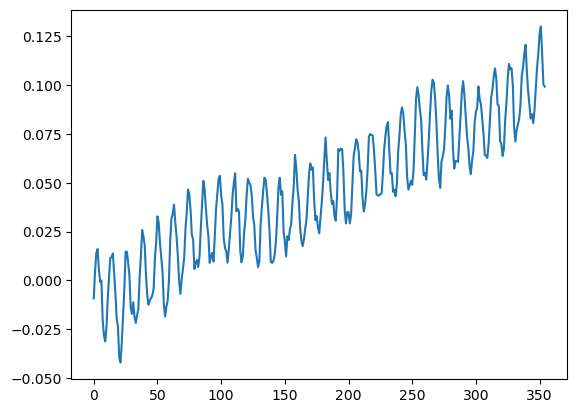

In [5]:
plt.plot(ssha.mean(dim='longitude').mean(dim='latitude'))

In [6]:
ssha_1=scp.get_anom(ssha,method=1)

In [7]:
ssha=ssha.groupby('time.month')-ssha.groupby('time.month').mean()

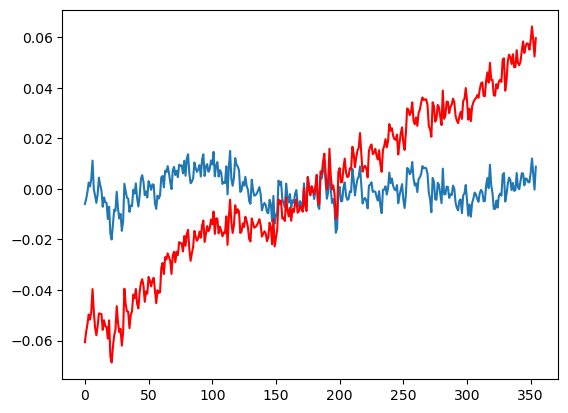

In [8]:
plt.plot(ssha_1.mean(dim='longitude').mean(dim='latitude'))
plt.plot(ssha.mean(dim='longitude').mean(dim='latitude'),color='red')

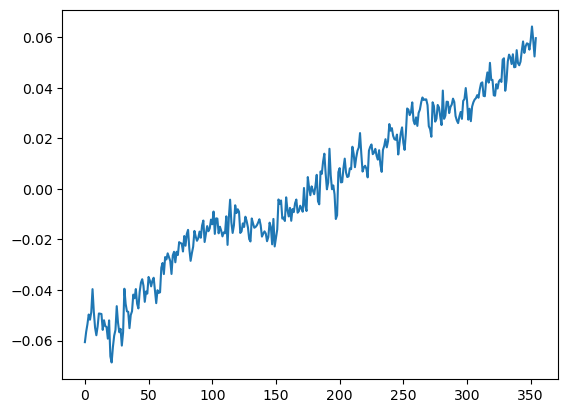

In [9]:
plt.plot(ssha.mean(dim='longitude').mean(dim='latitude'))

In [10]:
lon=ssha.longitude
lat=ssha.latitude
Lon,Lat=np.meshgrid(lon,lat)

In [11]:
ssha_84=ssha.loc['1984-12':'1985-2',:,:]
ssha_85=ssha.loc['1985-12':'1986-2',:,:]
ssha_86=ssha.loc['1986-12':'1987-2',:,:]
ssha_01=ssha.loc['2001-12':'2002-2',:,:]
ssha_17=ssha.loc['2017-12':'2018-2',:,:]
ssha_18=ssha.loc['2018-12':'2019-2',:,:]
ssha_21=ssha.loc['2021-12':'2022-2',:,:]

In [12]:
ssha_compose=xr.concat((ssha_84,ssha_85,ssha_86,ssha_01,ssha_17,ssha_18,ssha_21),dim='time')

In [13]:
ssha_compose_monthly=ssha_compose.groupby('time.month').mean()

In [14]:
ssha_compose.groupby('time.month')[1]

<xarray.DataArray 'sla' (time: 4, latitude: 161, longitude: 361)>
array([[[ 0.02549667,  0.00359   , -0.01273667, ..., -0.07717667,
         -0.08785667, -0.10618   ],
        [-0.00208667, -0.02028667, -0.03521667, ..., -0.06777   ,
         -0.08082   , -0.09841   ],
        [-0.02786667, -0.03856333, -0.04859667, ..., -0.06453667,
         -0.06644   , -0.06810333],
        ...,
        [        nan,         nan,         nan, ..., -0.04957333,
         -0.03991667, -0.02871667],
        [        nan,         nan,         nan, ..., -0.05223333,
         -0.03955   , -0.02575   ],
        [        nan,         nan,         nan, ..., -0.04957   ,
         -0.03693333, -0.02330667]],

       [[ 0.01999667,  0.00629   , -0.00063667, ...,  0.03542333,
          0.03074333,  0.01752   ],
        [-0.00078667, -0.00568667, -0.00841667, ...,  0.04713   ,
          0.04828   ,  0.04389   ],
        [-0.02326667, -0.02576333, -0.02949667, ...,  0.02896333,
          0.04386   ,  0.06519667],
...
        [        nan,         nan,         nan, ...,  0.09922667,
          0.08548333,  0.06778333],
        [        nan,         nan,         nan, ...,  0.09636667,
          0.08365   ,  0.06725   ],
        [        nan,         nan,         nan, ...,  0.08413   ,
          0.07406667,  0.06049333]],

       [[-0.01750333, -0.02061   , -0.01483667, ..., -0.10837667,
         -0.10395667, -0.10578   ],
        [-0.03498667, -0.03698667, -0.03131667, ..., -0.12457   ,
         -0.11212   , -0.09501   ],
        [-0.02886667, -0.02876333, -0.02249667, ..., -0.07933667,
         -0.06254   , -0.04700333],
        ...,
        [        nan,         nan,         nan, ...,  0.06592667,
          0.07438333,  0.08608333],
        [        nan,         nan,         nan, ...,  0.06386667,
          0.07225   ,  0.08365   ],
        [        nan,         nan,         nan, ...,  0.06273   ,
          0.06866667,  0.07669333]]])
Coordinates:
  * latitude   (latitude) float32 -59.88 -59.62 -59.38 ... -20.38 -20.12 -19.88
  * time       (time) datetime64[ns] 2002-01-15 2018-01-15 2019-01-15 2022-01-15
  * longitude  (longitude) float32 139.9 140.1 140.4 140.6 ... 229.4 229.6 229.9
    month      (time) int64 1 1 1 1

In [15]:
ssha_season=np.array(ssha_compose.groupby('time.season'))

C:\Users\Sebastian\AppData\Local\Temp\ipykernel_14508\3113609805.py:1: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  ssha_season=np.array(ssha_compose.groupby('time.season'))


In [16]:
ssha_compose_DJF=ssha_season[0,1].mean(dim='time')

detrend ssha

In [17]:
ssha_84=ssha_1.loc['1984-12':'1985-2',:,:]
ssha_85=ssha_1.loc['1985-12':'1986-2',:,:]
ssha_86=ssha_1.loc['1986-12':'1987-2',:,:]
ssha_01=ssha_1.loc['2001-12':'2002-2',:,:]
ssha_17=ssha_1.loc['2017-12':'2018-2',:,:]
ssha_18=ssha_1.loc['2018-12':'2019-2',:,:]
ssha_21=ssha_1.loc['2021-12':'2022-2',:,:]
ssha_compose=xr.concat((ssha_84,ssha_85,ssha_86,ssha_01,ssha_17,ssha_18,ssha_21),dim='time')
ssha_compose_monthly=ssha_compose.groupby('time.month').mean()
ssha_season=np.array(ssha_compose.groupby('time.season'))
ssha_compose_DJF=ssha_season[0,1].mean(dim='time')

C:\Users\Sebastian\AppData\Local\Temp\ipykernel_14508\169034254.py:10: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  ssha_season=np.array(ssha_compose.groupby('time.season'))


In [18]:
import cartopy.crs as ccrs  
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER 
import matplotlib.ticker as mticker 
from mpl_toolkits.axes_grid1.inset_locator import mark_inset 
import cartopy.feature as cfeature 
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap#调色用的

In [19]:
np.nanmax(ssha_compose_monthly[0])

0.1992170689655173

T检验

In [20]:
from scipy.stats.mstats import ttest_ind

In [21]:
ssha_compose.groupby('time.season')['DJF']

<xarray.DataArray 'sla' (time: 12, latitude: 161, longitude: 361)>
array([[[ 0.07944453,  0.05536236,  0.03454759, ..., -0.10060079,
         -0.09588808, -0.0939069 ],
        [ 0.03337419,  0.01321163, -0.00770709, ..., -0.08322325,
         -0.08002473, -0.08075271],
        [-0.0024931 , -0.01604315, -0.02858227, ...,  0.02656315,
          0.00660788, -0.01029429],
        ...,
        [        nan,         nan,         nan, ..., -0.01819271,
         -0.02847961, -0.03411744],
        [        nan,         nan,         nan, ..., -0.02315212,
         -0.03466296, -0.04147704],
        [        nan,         nan,         nan, ..., -0.02384177,
         -0.03400552, -0.0397598 ]],

       [[ 0.0428949 ,  0.02252309,  0.00756733, ..., -0.07715036,
         -0.08791601, -0.10575664],
        [ 0.01786114,  0.00134283, -0.01273641, ..., -0.06817244,
         -0.07989987, -0.09472127],
        [-0.00741499, -0.01737885, -0.02735859, ..., -0.06514907,
         -0.06679924, -0.06592719],
...
        [        nan,         nan,         nan, ...,  0.03875957,
          0.04614882,  0.05664946],
        [        nan,         nan,         nan, ...,  0.03730215,
          0.04510839,  0.05630452],
        [        nan,         nan,         nan, ...,  0.03746581,
          0.04361763,  0.05253785]],

       [[-0.0551557 , -0.05840989, -0.06391763, ..., -0.01648989,
         -0.02199355, -0.0290043 ],
        [-0.08972774, -0.09115527, -0.08894667, ..., -0.04987892,
         -0.0671871 , -0.07797441],
        [-0.10369828, -0.09866151, -0.0879329 , ..., -0.06909312,
         -0.09032753, -0.10020086],
        ...,
        [        nan,         nan,         nan, ...,  0.07387355,
          0.07192473,  0.06709505],
        [        nan,         nan,         nan, ...,  0.07817118,
          0.07646043,  0.07090968],
        [        nan,         nan,         nan, ...,  0.07625269,
          0.07302903,  0.0652    ]]])
Coordinates:
  * latitude   (latitude) float32 -59.88 -59.62 -59.38 ... -20.38 -20.12 -19.88
  * time       (time) datetime64[ns] 2001-12-15 2002-01-15 ... 2022-02-15
  * longitude  (longitude) float32 139.9 140.1 140.4 140.6 ... 229.4 229.6 229.9

In [22]:
ssha_clim=ssha.groupby('time.month').mean()

In [23]:
np.tile(ssha_clim[0],(4,1,1)).shape

(4, 161, 361)

In [24]:
ssha_djf_clim=np.concatenate((np.tile(ssha_clim[11],(4,1,1)),np.tile(ssha_clim[0],(4,1,1)),np.tile(ssha_clim[1],(4,1,1))),axis=0)

In [25]:
_, p_sla12=ttest_ind(ssha_compose.groupby('time.month')[12],np.tile(ssha_clim[11],(4,1,1)),equal_var=True)

In [26]:
_, p_sla1=ttest_ind(ssha_compose.groupby('time.month')[1],np.tile(ssha_clim[0],(4,1,1)),equal_var=True)

In [27]:
_, p_sla2=ttest_ind(ssha_compose.groupby('time.month')[2],np.tile(ssha_clim[1],(4,1,1)),equal_var=True)

In [28]:
_, p_slaDJF=ttest_ind(ssha_compose.groupby('time.season')['DJF'],ssha_djf_clim,equal_var=True)

In [29]:
np.nanmax(ssha_compose_monthly[2])

0.18894980295566505

In [30]:
ssha_compose_monthly[2]

<xarray.DataArray 'sla' (latitude: 161, longitude: 361)>
array([[ 0.01610381,  0.01020826,  0.00634207, ..., -0.03752692,
        -0.04165521, -0.04845862],
       [ 0.01397243,  0.01018523,  0.00544392, ..., -0.02447521,
        -0.02743894, -0.03324766],
       [ 0.00392543, -0.00043105, -0.00630936, ...,  0.02224036,
         0.01689637,  0.0073066 ],
       ...,
       [        nan,         nan,         nan, ...,  0.02929794,
         0.02682622,  0.02538831],
       [        nan,         nan,         nan, ...,  0.02942447,
         0.02747305,  0.02545401],
       [        nan,         nan,         nan, ...,  0.02575421,
         0.02437621,  0.02287557]])
Coordinates:
  * latitude   (latitude) float32 -59.88 -59.62 -59.38 ... -20.38 -20.12 -19.88
  * longitude  (longitude) float32 139.9 140.1 140.4 140.6 ... 229.4 229.6 229.9
    month      int64 12

In [31]:
import matplotlib.colors as mcolors
import matplotlib as mpl

c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\gridliner.py:307: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\gridliner.py:343: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '
c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\geoaxes.py:1508: UserWarning: The following kwargs were not used by contour: 'color'
  result = matplotlib.axes.Axes.contourf(self, *args, **kwargs)
c:\Users\Sebastian\miniconda3\envs\sheep\lib\site-packages\cartopy\mpl\geoaxes.py:1508: UserWarning: The following kwargs were not used by contour: 'linewidth', 'color'
  result = matplotlib.axes.Axes.contourf(self, *args, **kwargs)


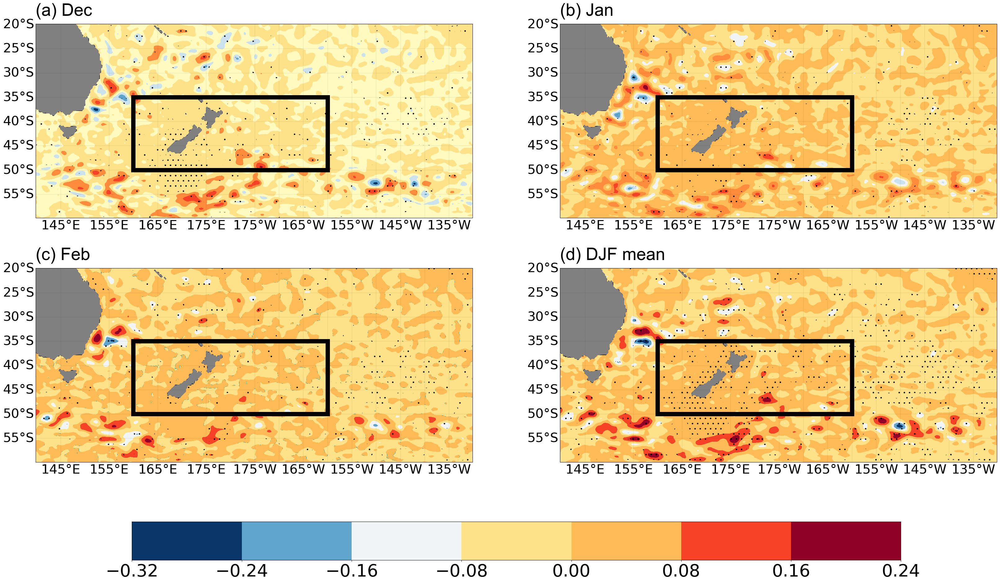

In [32]:
#plt.figure(figsize=[20,5])

proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(40,25),subplot_kw={'projection': proj})

#添加框线
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE1=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE2=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE3=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25



for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap='Oranges_r')
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        
        #ax[i][j].set_xticks(np.arange(-20,21,10))
        gl.xlabel_style = {'size': 30, "color": 'k'}     
        gl.ylabel_style = {'size': 30, "color": 'k'}
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(135,180,10),np.arange(-175,-130,5)]))
        gl.ylocator = mticker.FixedLocator(np.arange(-60, -17,5))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER

# 创建粉红色系的颜色列表
colors = ['#fffac0', '#ffefa4', '#fee289', '#fed470', '#febb56','#fea446','#fe8c3c','#fc6631','#f64227','#e6211e','#d10e21','#b70026','#910026']
colors = ['#08366a','#246aae','#5fa5cd','#cae1ee','#f2f5f6','#fffac0', '#fee289','#febb56','#fe8c3c','#f64227','#d10e21','#910026']
# 创建颜色映射
cmap = ListedColormap(colors)


ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], cmap=cmap,transform=ccrs.PlateCarree(0))
#ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2],[-0.1,0.1], color='grey',transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], cmap=cmap,transform=ccrs.PlateCarree(0))
#ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0],[-0.000001,0.000001], color='white',transform=ccrs.PlateCarree(0))
c=ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], cmap=cmap,transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1],[-0.000001,0.000001], color='white',transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,cmap=cmap,transform=ccrs.PlateCarree(0))
#ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,[-0.000001,0.000001], color='white',transform=ccrs.PlateCarree(0))


clp=ax[0][0].contourf(Lon,Lat,p_sla12,levels =[0,0.05],hatches=['.'],linewidth=10,zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[0][1].contourf(Lon,Lat,p_sla1,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][0].contourf(Lon,Lat,p_sla2,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][1].contourf(Lon,Lat,p_slaDJF,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)


ax[0][0].set_title('(a) Dec',fontsize=40,fontname='Arial',loc='left')
ax[0][1].set_title('(b) Jan',fontsize=40,fontname='Arial',loc='left')
ax[1][0].set_title('(c) Feb',fontsize=40,fontname='Arial',loc='left')
ax[1][1].set_title('(d) DJF mean',fontsize=40,fontname='Arial',loc='left')

ax[0][0].add_patch(RE)  #添加矩形框，如果这一句求掉了就没有框显示了
ax[0][1].add_patch(RE1)
ax[1][0].add_patch(RE2)
ax[1][1].add_patch(RE3)


RE.set_linewidth(10)
RE1.set_linewidth(10)
RE2.set_linewidth(10)
RE3.set_linewidth(10)

cb=plt.colorbar(c, ax=ax.ravel().tolist(),   # type:ignore
                orientation='horizontal',shrink=0.8,pad=0.1,extend='max')


font = {'family' : 'serif',
        'color'  : 'darkred',
        'weight' : 'normal',
        'size'   : 40,}
#plt.clabel(d,fontsize=30,colors='black')
#plt.clabel(e,fontsize=30,colors='black')
#plt.clabel(f,fontsize=30,colors='black')
#plt.clabel(g,fontsize=30,colors='black')
#cb.set_label('STD of SSTA',fontdict=font) 
cb.ax.tick_params(labelsize=40)
plt.show()

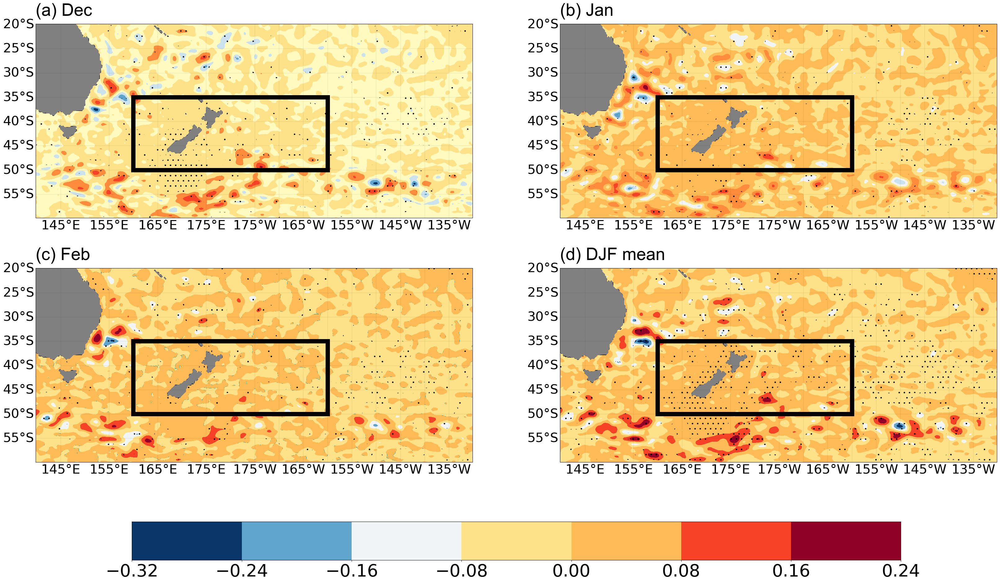

In [33]:
#plt.figure(figsize=[20,5])

proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(40,25),subplot_kw={'projection': proj})

#添加框线
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE1=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE2=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE3=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25



for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap='Oranges_r')
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        
        #ax[i][j].set_xticks(np.arange(-20,21,10))
        gl.xlabel_style = {'size': 30, "color": 'k'}     
        gl.ylabel_style = {'size': 30, "color": 'k'}
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(135,180,10),np.arange(-175,-130,5)]))
        gl.ylocator = mticker.FixedLocator(np.arange(-60, -17,5))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER

# 创建粉红色系的颜色列表
colors = ['#fffac0', '#ffefa4', '#fee289', '#fed470', '#febb56','#fea446','#fe8c3c','#fc6631','#f64227','#e6211e','#d10e21','#b70026','#910026']
colors =['#08366a','#246aae','#5fa5cd','#cae1ee','#f2f5f6','#fffac0', '#fee289','#febb56','#fe8c3c','#f64227','#d10e21','#910026']
# 创建颜色映射
cmap = ListedColormap(colors)





ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], cmap=cmap,transform=ccrs.PlateCarree(0))
#ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2],[-0.1,0.1], color='grey',transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], cmap=cmap,transform=ccrs.PlateCarree(0))
#ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0],[-0.000001,0.000001], color='white',transform=ccrs.PlateCarree(0))
c=ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], cmap=cmap,transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1],[-0.000001,0.000001], color='white',transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,cmap=cmap,transform=ccrs.PlateCarree(0))
#ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,[-0.000001,0.000001], color='white',transform=ccrs.PlateCarree(0))


clp=ax[0][0].contourf(Lon,Lat,p_sla12,levels =[0,0.05],hatches=['.'],linewidth=10,zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[0][1].contourf(Lon,Lat,p_sla1,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][0].contourf(Lon,Lat,p_sla2,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][1].contourf(Lon,Lat,p_slaDJF,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)


ax[0][0].set_title('(a) Dec',fontsize=40,fontname='Arial',loc='left')
ax[0][1].set_title('(b) Jan',fontsize=40,fontname='Arial',loc='left')
ax[1][0].set_title('(c) Feb',fontsize=40,fontname='Arial',loc='left')
ax[1][1].set_title('(d) DJF mean',fontsize=40,fontname='Arial',loc='left')

ax[0][0].add_patch(RE)  #添加矩形框，如果这一句求掉了就没有框显示了
ax[0][1].add_patch(RE1)
ax[1][0].add_patch(RE2)
ax[1][1].add_patch(RE3)


RE.set_linewidth(10)
RE1.set_linewidth(10)
RE2.set_linewidth(10)
RE3.set_linewidth(10)

cb=plt.colorbar(c, ax=ax.ravel().tolist(),   # type:ignore
                orientation='horizontal',shrink=0.8,pad=0.1,extend='max')


font = {'family' : 'serif',
        'color'  : 'darkred',
        'weight' : 'normal',
        'size'   : 40,}
#plt.clabel(d,fontsize=30,colors='black')
#plt.clabel(e,fontsize=30,colors='black')
#plt.clabel(f,fontsize=30,colors='black')
#plt.clabel(g,fontsize=30,colors='black')
#cb.set_label('STD of SSTA',fontdict=font) 
cb.ax.tick_params(labelsize=40)
plt.show()

In [34]:
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.ticker as ticker

In [35]:
vmin, vmax = -0.28, 0.28
# 创建颜色映射
levels = np.linspace(vmin, vmax, 15)
levels

array([-0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
        0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28])

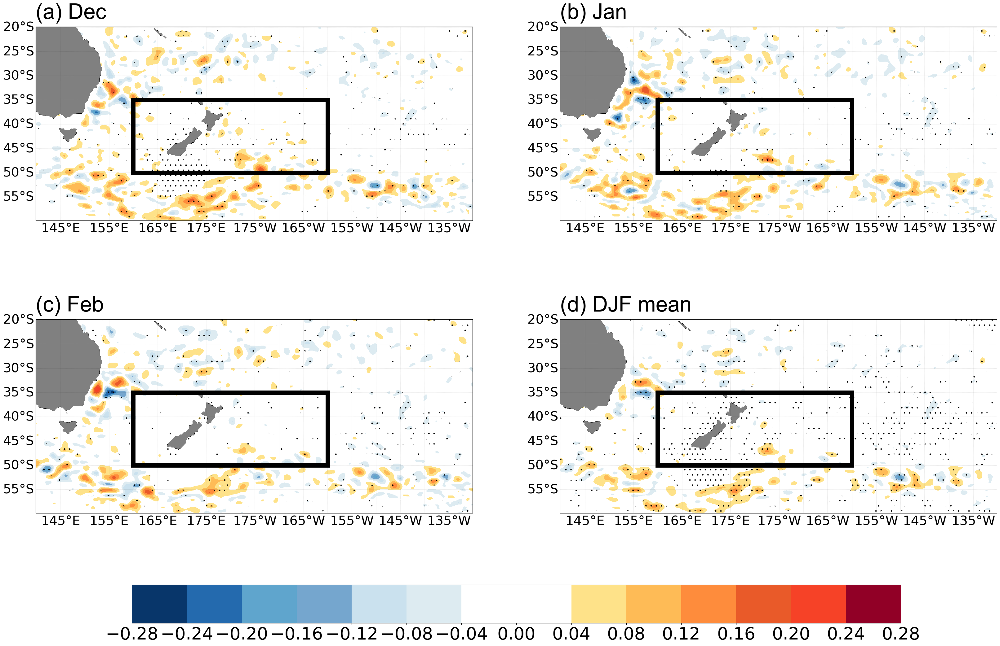

In [36]:
proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(40,30),subplot_kw={'projection': proj})

#添加框线
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE1=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE2=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE3=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25





for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap='Oranges_r')
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        
        #ax[i][j].set_xticks(np.arange(-20,21,10))
        gl.xlabel_style = {'size': 30, "color": 'k'}     
        gl.ylabel_style = {'size': 30, "color": 'k'}
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(135,180,10),np.arange(-175,-130,5)]))
        gl.ylocator = mticker.FixedLocator(np.arange(-60, -17,5))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER


colors =['#08366a','#246aae','#5fa5cd','#75A6CE','#cae1ee','#DDEBF1','#ffffff','#ffffff', '#fee289','#febb56','#fe8c3c','#E95A29','#f64227','#d10e21','#910026']
#colors=['#08366a','#246aae','#5fa5cd','#75A6CE','#cae1ee','#DDEBF1','#f2f5f6','#E7B3DA','#F499A9','#e98b6e', '#d25d4d', '#ca4c43', '#b53438', '#ab2733']



# 创建颜色映射
cmap = ListedColormap(colors)
# 设置颜色映射范围
vmin, vmax = -0.28, 0.28
# 创建颜色映射
#levels = np.linspace(vmin, vmax, 15)
levels=[-0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0. ,  0.04,
        0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28]
norm = BoundaryNorm(levels, cmap.N)


ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2],[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0],[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1],[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))
c=ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))


clp=ax[0][0].contourf(Lon,Lat,p_sla12,levels =[0,0.05],hatches=['.'],linewidth=10,zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[0][1].contourf(Lon,Lat,p_sla1,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][0].contourf(Lon,Lat,p_sla2,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][1].contourf(Lon,Lat,p_slaDJF,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)

ax[0][0].set_title('(a) Dec',fontsize=50,fontname='Arial',loc='left')
ax[0][1].set_title('(b) Jan',fontsize=50,fontname='Arial',loc='left')
ax[1][0].set_title('(c) Feb',fontsize=50,fontname='Arial',loc='left')
ax[1][1].set_title('(d) DJF mean',fontsize=50,fontname='Arial',loc='left')

ax[0][0].add_patch(RE)  #添加矩形框，如果这一句求掉了就没有框显示了
ax[0][1].add_patch(RE1)
ax[1][0].add_patch(RE2)
ax[1][1].add_patch(RE3)


RE.set_linewidth(10)
RE1.set_linewidth(10)
RE2.set_linewidth(10)
RE3.set_linewidth(10)

cb=plt.colorbar(c, ax=ax.ravel().tolist(),   # type:ignore
                orientation='horizontal',shrink=0.8,pad=0.1,extend='max',ticks=[-0.28, -0.24, -0.2, -0.16, -0.12, -0.08, -0.04, 0.0, 0.04, 0.08, 0.12, 0.16, 0.2, 0.24, 0.28])


font = {'family' : 'serif',
        'color'  : 'darkred',
        'weight' : 'normal',
        'size'   : 40,}
#plt.clabel(d,fontsize=30,colors='black')
#plt.clabel(e,fontsize=30,colors='black')
#plt.clabel(f,fontsize=30,colors='black')
#plt.clabel(g,fontsize=30,colors='black')
#cb.set_label('STD of SSTA',fontdict=font) 
cb.ax.tick_params(labelsize=40)
# 设置colorbar的刻度间隔
#cb.ax.xaxis.set_major_locator(ticker.MultipleLocator(0.04))
plt.show()

['#5fa5cd', '#75b0d3', '#89bbd9', '#9dc7df', '#b0d2e5', '#bfd9ea', '#cde0ef', '#dae7f4', '#e5ecf7', '#eff2fa', '#f8f8fc', '#ffffff', '#ffffff', '#ffffff', '#fff4fd', '#ffe8ee', '#ffded3', '#ffdbb5', '#ffd39b', '#fdcb81', '#f9c466', '#f6ac50', '#f2933d', '#ee7830', '#e95a29']


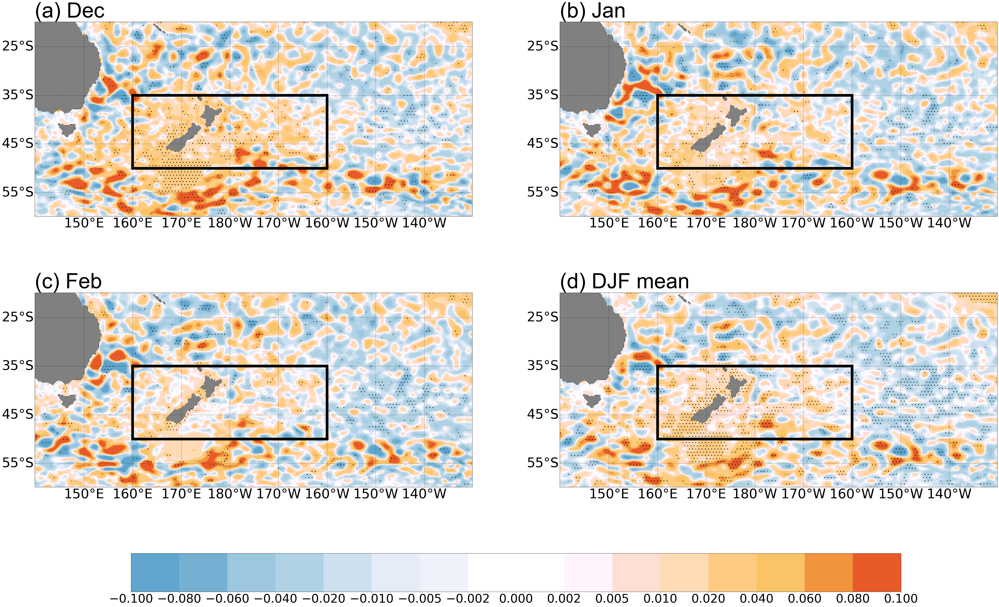

In [50]:
proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(65,45),subplot_kw={'projection': proj})

#添加框线
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE1=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE2=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE3=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25

for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap='Oranges_r')
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=1, color='black', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        ax[i][j].tick_params(pad=3)
        #ax[i][j].set_xticks(np.arange(-20,21,10))
        gl.xlabel_style = {'size': 50, "color": 'k'}     
        gl.ylabel_style = {'size': 50, "color": 'k'}
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(150,180,10),np.arange(-180,-130,10)]))
        gl.ylocator = mticker.FixedLocator(np.arange(-65, -17,10))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER
        #gl.xlabel_bottom = 
        ##调整经度纬度距离图片的距离
        #gl.xlabel_verticalalignment = 'bottom'
        #gl.xlabel_x = -3

colors =['#08366a','#246aae','#5fa5cd','#75A6CE','#cae1ee','#E9EFF8','#ffffff','#ffffff', '#FFDBB5','#fee289','#febb56','#fe8c3c','#E95A29','#f64227','#d10e21']
#colors=['#08366a','#246aae','#5fa5cd','#75A6CE','#cae1ee','#DDEBF1','#f2f5f6','#E7B3DA','#F499A9','#e98b6e', '#d25d4d', '#ca4c43', '#b53438', '#ab2733']
colors = ['#5fa5cd', '#75b0d3', '#89bbd9', '#9dc7df', '#b0d2e5', '#bfd9ea', '#cde0ef', '#dae7f4', '#e5ecf7', '#eff2fa', '#f8f8fc', '#ffffff','#ffffff','#ffffff', '#fff4fd', '#ffe8ee', '#ffded3', '#ffdbb5', '#ffd39b', '#fdcb81', '#f9c466', '#f6ac50', '#f2933d', '#ee7830', '#e95a29']
print(colors)


# 创建颜色映射
cmap = ListedColormap(colors)
# 设置颜色映射范围
vmin, vmax = -0.28, 0.28
# 创建颜色映射
#levels = np.linspace(vmin, vmax, 15)
levels=[-0.1,  -0.08,-0.06,-0.04,-0.02,-0.01,-0.005,-0.002,0.,0.002,0.005,0.01,0.02,0.04,0.06,0.08,0.1]
norm = BoundaryNorm(levels, cmap.N)


ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2],[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0],[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1],[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))
c=ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))

###HAN###
ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], colors='#e95a29',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], colors='#e95a29',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], colors='#e95a29',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,colors='#e95a29',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], colors='#5fa5cd',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], colors='#5fa5cd',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], colors='#5fa5cd',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,colors='#5fa5cd',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
###HAN###


clp=ax[0][0].contourf(Lon,Lat,p_sla12,levels =[0,0.05],hatches=['.'],linewidth=10,zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[0][1].contourf(Lon,Lat,p_sla1,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][0].contourf(Lon,Lat,p_sla2,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][1].contourf(Lon,Lat,p_slaDJF,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)

ax[0][0].set_title('(a) Dec',fontsize=80,fontname='Arial',loc='left')
ax[0][1].set_title('(b) Jan',fontsize=80,fontname='Arial',loc='left')
ax[1][0].set_title('(c) Feb',fontsize=80,fontname='Arial',loc='left')
ax[1][1].set_title('(d) DJF mean',fontsize=80,fontname='Arial',loc='left')

ax[0][0].add_patch(RE)  #添加矩形框，如果这一句求掉了就没有框显示了
ax[0][1].add_patch(RE1)
ax[1][0].add_patch(RE2)
ax[1][1].add_patch(RE3)


#调整经度纬度距离图片的距离
#ax[0][0].tick_params(axis='x',pad=500)
#ax[0][0].grid(linewidth=5, color='green', alpha=1, linestyle='--')



RE.set_linewidth(10)
RE1.set_linewidth(10)
RE2.set_linewidth(10)
RE3.set_linewidth(10)

cb=plt.colorbar(c, ax=ax.ravel().tolist(),   # type:ignore
                orientation='horizontal',shrink=0.8,pad=0.1,extend='max',ticks=[-0.1,  -0.08,-0.06,-0.04,-0.02,-0.01,-0.005,-0.002,0.,0.002,0.005,0.01,0.02,0.04,0.06,0.08,0.1])


font = {'family' : 'serif',
        'color'  : 'darkred',
        'weight' : 'normal',
        'size'   : 40,}

for i in range(0,2,1):
    for j in range(0,2,1):
        #设置边框线
        ax[i][j].spines['bottom'].set_linewidth(100.0)#设置边框线宽为2.0
        ax[i][j].spines['bottom'].set_linestyle("--")
        ax[i][j].spines['bottom'].set_color('red')
cb.ax.tick_params(labelsize=45)
# 设置colorbar的刻度间隔
#cb.ax.xaxis.set_major_locator(ticker.MultipleLocator(0.04)



plt.show()

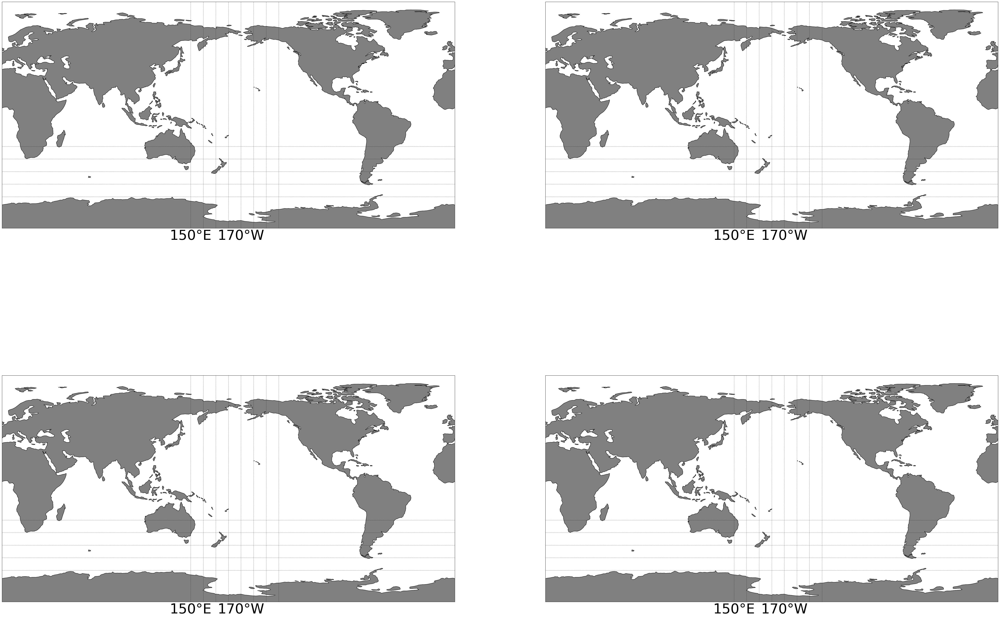

In [42]:
proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(65,45),subplot_kw={'projection': proj})

#添加框线
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE1=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE2=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE3=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25

for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap='Oranges_r')
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.4, color='k', alpha=1, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        ax[i][j].tick_params(pad=3)
        #ax[i][j].set_xticks(np.arange(-20,21,10))
        gl.xlabel_style = {'size': 50, "color": 'k'}     
        gl.ylabel_style = {'size': 50, "color": 'k'}
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(150,180,10),np.arange(-180,-130,10)]))
        gl.ylocator = mticker.FixedLocator(np.arange(-65, -17,10))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER
        #gl.xlabel_bottom = 
        ##调整经度纬度距离图片的距离
        #gl.xlabel_verticalalignment = 'bottom'
        #gl.xlabel_x = -3

['#5fa5cd', '#75b0d3', '#89bbd9', '#9dc7df', '#b0d2e5', '#bfd9ea', '#cde0ef', '#dae7f4', '#e5ecf7', '#eff2fa', '#f8f8fc', '#ffffff', '#ffffff', '#ffffff', '#fff4fd', '#ffe8ee', '#ffded3', '#ffdbb5', '#ffd39b', '#fdcb81', '#f9c466', '#f6ac50', '#f2933d', '#ee7830', '#e95a29']


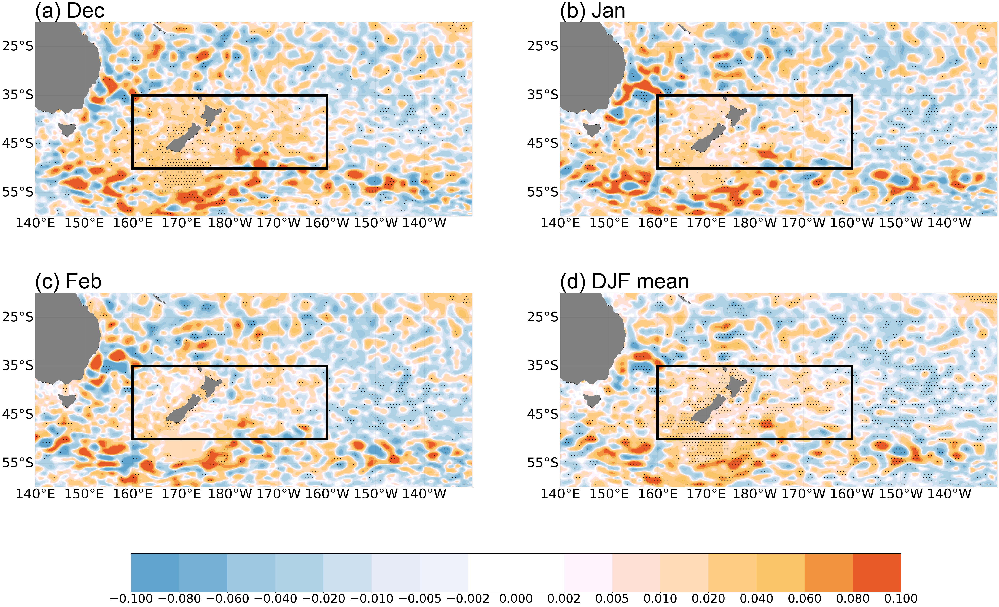

In [38]:
proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(65,45),subplot_kw={'projection': proj})

#添加框线
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE1=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE2=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE3=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25

for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap='Oranges_r')
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        ax[i][j].tick_params(pad=3)
        #ax[i][j].set_xticks(np.arange(-20,21,10))
        gl.xlabel_style = {'size': 50, "color": 'k'}     
        gl.ylabel_style = {'size': 50, "color": 'k'}
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(140,180,10),np.arange(-180,-130,10)]))
        gl.ylocator = mticker.FixedLocator(np.arange(-65, -17,10))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER
        #gl.xlabel_bottom = 
        ##调整经度纬度距离图片的距离
        #gl.xlabel_verticalalignment = 'bottom'
        #gl.xlabel_x = -3

colors =['#08366a','#246aae','#5fa5cd','#75A6CE','#cae1ee','#E9EFF8','#ffffff','#ffffff', '#FFDBB5','#fee289','#febb56','#fe8c3c','#E95A29','#f64227','#d10e21']
#colors=['#08366a','#246aae','#5fa5cd','#75A6CE','#cae1ee','#DDEBF1','#f2f5f6','#E7B3DA','#F499A9','#e98b6e', '#d25d4d', '#ca4c43', '#b53438', '#ab2733']
colors = ['#5fa5cd', '#75b0d3', '#89bbd9', '#9dc7df', '#b0d2e5', '#bfd9ea', '#cde0ef', '#dae7f4', '#e5ecf7', '#eff2fa', '#f8f8fc', '#ffffff','#ffffff','#ffffff', '#fff4fd', '#ffe8ee', '#ffded3', '#ffdbb5', '#ffd39b', '#fdcb81', '#f9c466', '#f6ac50', '#f2933d', '#ee7830', '#e95a29']
print(colors)


# 创建颜色映射
cmap = ListedColormap(colors)
# 设置颜色映射范围
vmin, vmax = -0.28, 0.28
# 创建颜色映射
#levels = np.linspace(vmin, vmax, 15)
levels=[-0.1,  -0.08,-0.06,-0.04,-0.02,-0.01,-0.005,-0.002,0.,0.002,0.005,0.01,0.02,0.04,0.06,0.08,0.1]
norm = BoundaryNorm(levels, cmap.N)


ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2],[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0],[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1],[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))
c=ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))

###HAN###
ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], colors='#e95a29',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], colors='#e95a29',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], colors='#e95a29',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,colors='#e95a29',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], colors='#5fa5cd',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], colors='#5fa5cd',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], colors='#5fa5cd',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,colors='#5fa5cd',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
###HAN###


clp=ax[0][0].contourf(Lon,Lat,p_sla12,levels =[0,0.05],hatches=['.'],linewidth=10,zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[0][1].contourf(Lon,Lat,p_sla1,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][0].contourf(Lon,Lat,p_sla2,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][1].contourf(Lon,Lat,p_slaDJF,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)

ax[0][0].set_title('(a) Dec',fontsize=80,fontname='Arial',loc='left')
ax[0][1].set_title('(b) Jan',fontsize=80,fontname='Arial',loc='left')
ax[1][0].set_title('(c) Feb',fontsize=80,fontname='Arial',loc='left')
ax[1][1].set_title('(d) DJF mean',fontsize=80,fontname='Arial',loc='left')

ax[0][0].add_patch(RE)  #添加矩形框，如果这一句求掉了就没有框显示了
ax[0][1].add_patch(RE1)
ax[1][0].add_patch(RE2)
ax[1][1].add_patch(RE3)


#调整经度纬度距离图片的距离
#ax[0][0].tick_params(axis='x',pad=500)




RE.set_linewidth(10)
RE1.set_linewidth(10)
RE2.set_linewidth(10)
RE3.set_linewidth(10)

cb=plt.colorbar(c, ax=ax.ravel().tolist(),   # type:ignore
                orientation='horizontal',shrink=0.8,pad=0.1,extend='max',ticks=[-0.1,  -0.08,-0.06,-0.04,-0.02,-0.01,-0.005,-0.002,0.,0.002,0.005,0.01,0.02,0.04,0.06,0.08,0.1])


font = {'family' : 'serif',
        'color'  : 'darkred',
        'weight' : 'normal',
        'size'   : 40,}

for i in range(0,2,1):
    for j in range(0,2,1):
        #设置边框线
        ax[i][j].spines['bottom'].set_linewidth(100.0)#设置边框线宽为2.0
        ax[i][j].spines['bottom'].set_linestyle("--")
        ax[i][j].spines['bottom'].set_color('red')
cb.ax.tick_params(labelsize=45)
# 设置colorbar的刻度间隔
#cb.ax.xaxis.set_major_locator(ticker.MultipleLocator(0.04)



plt.show()

['#394b6a', '#75b0d3', '#89bbd9', '#9dc7df', '#b0d2e5', '#bfd9ea', '#cde0ef', '#dae7f4', '#e5ecf7', '#eff2fa', '#f8f8fc', '#ffffff', '#ffffff', '#ffffff', '#fff4fd', '#ffe8ee', '#ffded3', '#ffdbb5', '#ffd39b', '#fdcb81', '#f9c466', '#f6ac50', '#f2933d', '#ee7830', '#8f666f']


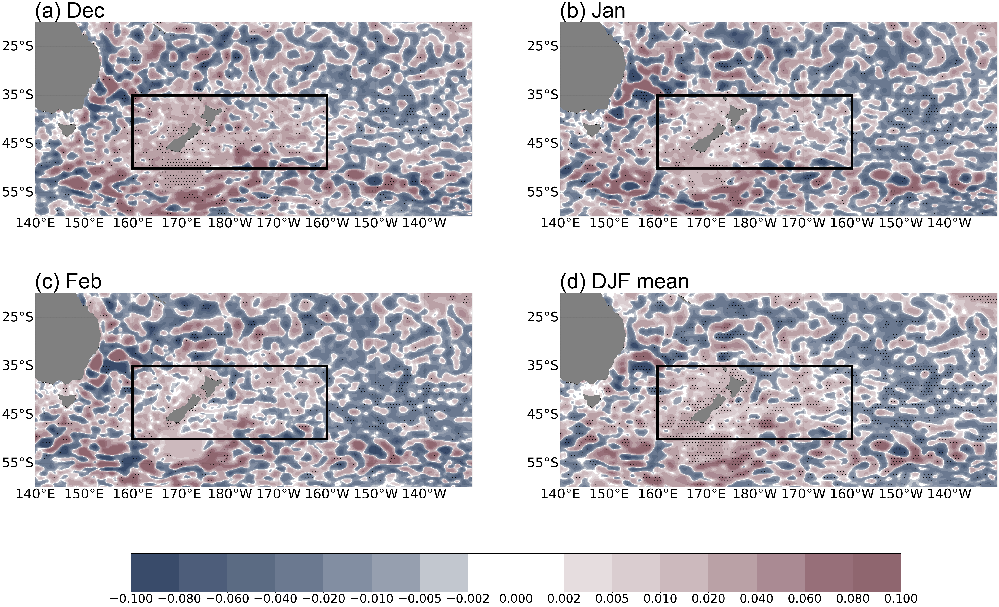

In [47]:
proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(65,45),subplot_kw={'projection': proj})

#添加框线
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE1=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE2=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE3=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25

for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap='Oranges_r')
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        ax[i][j].tick_params(pad=3)
        #ax[i][j].set_xticks(np.arange(-20,21,10))
        gl.xlabel_style = {'size': 50, "color": 'k'}     
        gl.ylabel_style = {'size': 50, "color": 'k'}
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.arange(140,180,10),np.arange(-180,-130,10)]))
        gl.ylocator = mticker.FixedLocator(np.arange(-65, -17,10))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER
        #gl.xlabel_bottom = 
        ##调整经度纬度距离图片的距离
        #gl.xlabel_verticalalignment = 'bottom'
        #gl.xlabel_x = -3

colors =['#08366a','#246aae','#394b6a','#75A6CE','#cae1ee','#E9EFF8','#ffffff','#ffffff', '#FFDBB5','#fee289','#febb56','#fe8c3c','#8f666f','#f64227','#d10e21']
#colors=['#08366a','#246aae','#394b6a','#75A6CE','#cae1ee','#DDEBF1','#f2f5f6','#E7B3DA','#F499A9','#e98b6e', '#d25d4d', '#ca4c43', '#b53438', '#ab2733']
colors = ['#394b6a', '#75b0d3', '#89bbd9', '#9dc7df', '#b0d2e5', '#bfd9ea', '#cde0ef', '#dae7f4', '#e5ecf7', '#eff2fa', '#f8f8fc', '#ffffff','#ffffff','#ffffff', '#fff4fd', '#ffe8ee', '#ffded3', '#ffdbb5', '#ffd39b', '#fdcb81', '#f9c466', '#f6ac50', '#f2933d', '#ee7830', '#8f666f']
print(colors)
colors = ['#394b6a','#4d5d7A','#5b6b83','#6b7990','#828ea2','#969faf','#c2c7cf','#ffffff','#ffffff','#e6dddf','#dacdd0','#ccb9bd','#baa1a6','#aa8a93','#976f79','#8f666f']

# 创建颜色映射
cmap = ListedColormap(colors)
# 设置颜色映射范围
vmin, vmax = -0.28, 0.28
# 创建颜色映射
#levels = np.linspace(vmin, vmax, 15)
levels=[-0.1,  -0.08,-0.06,-0.04,-0.02,-0.01,-0.005,-0.002,0.,0.002,0.005,0.01,0.02,0.04,0.06,0.08,0.1]
norm = BoundaryNorm(levels, cmap.N)


ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2],[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0],[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1],[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))
c=ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,cmap=cmap,norm=norm,levels=levels,transform=ccrs.PlateCarree(0))
#ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,[-0.0001,0.0001], colors='white',transform=ccrs.PlateCarree(0))

###HAN###
ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], colors='#8f666f',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], colors='#8f666f',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], colors='#8f666f',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,colors='#8f666f',norm=norm,levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], colors='#394b6a',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], colors='#394b6a',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], colors='#394b6a',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,colors='#394b6a',norm=norm,levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
###HAN###


clp=ax[0][0].contourf(Lon,Lat,p_sla12,levels =[0,0.05],hatches=['.'],linewidth=10,zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[0][1].contourf(Lon,Lat,p_sla1,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][0].contourf(Lon,Lat,p_sla2,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][1].contourf(Lon,Lat,p_slaDJF,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)

ax[0][0].set_title('(a) Dec',fontsize=80,fontname='Arial',loc='left')
ax[0][1].set_title('(b) Jan',fontsize=80,fontname='Arial',loc='left')
ax[1][0].set_title('(c) Feb',fontsize=80,fontname='Arial',loc='left')
ax[1][1].set_title('(d) DJF mean',fontsize=80,fontname='Arial',loc='left')

ax[0][0].add_patch(RE)  #添加矩形框，如果这一句求掉了就没有框显示了
ax[0][1].add_patch(RE1)
ax[1][0].add_patch(RE2)
ax[1][1].add_patch(RE3)


#调整经度纬度距离图片的距离
#ax[0][0].tick_params(axis='x',pad=500)




RE.set_linewidth(10)
RE1.set_linewidth(10)
RE2.set_linewidth(10)
RE3.set_linewidth(10)

cb=plt.colorbar(c, ax=ax.ravel().tolist(),   # type:ignore
                orientation='horizontal',shrink=0.8,pad=0.1,extend='max',ticks=[-0.1,  -0.08,-0.06,-0.04,-0.02,-0.01,-0.005,-0.002,0.,0.002,0.005,0.01,0.02,0.04,0.06,0.08,0.1])


font = {'family' : 'serif',
        'color'  : 'darkred',
        'weight' : 'normal',
        'size'   : 40,}

for i in range(0,2,1):
    for j in range(0,2,1):
        #设置边框线
        ax[i][j].spines['bottom'].set_linewidth(100.0)#设置边框线宽为2.0
        ax[i][j].spines['bottom'].set_linestyle("--")
        ax[i][j].spines['bottom'].set_color('red')
cb.ax.tick_params(labelsize=45)
# 设置colorbar的刻度间隔
#cb.ax.xaxis.set_major_locator(ticker.MultipleLocator(0.04)



plt.show()

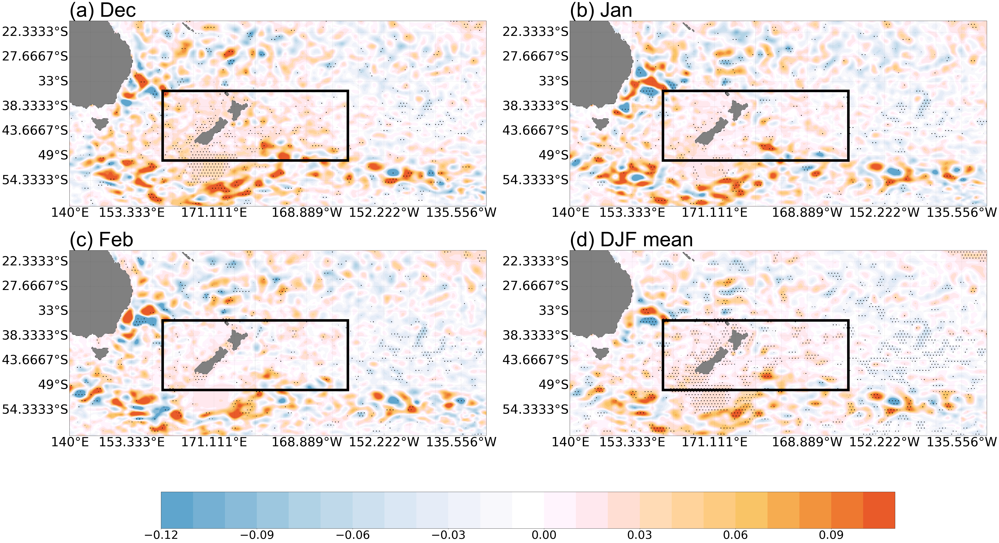

In [39]:
proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(65,40),subplot_kw={'projection': proj})

#添加框线
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE1=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE2=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE3=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25

for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap='Oranges_r')
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        
        #ax[i][j].set_xticks(np.linspace(-20,21,10))
        gl.xlabel_style = {'size': 50, "color": 'k'}     
        gl.ylabel_style = {'size': 50, "color": 'k'}
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.linspace(140,180,10),np.linspace(-180,-130,10)]))
        gl.ylocator = mticker.FixedLocator(np.linspace(-65, -17,10))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER

# colors =['#08366a','#246aae','#5fa5cd','#75A6CE','#cae1ee','#E9EFF8','#ffffff','#ffffff', '#FFDBB5','#fee289','#febb56','#fe8c3c','#E95A29','#f64227','#d10e21']
#colors=['#08366a','#246aae','#5fa5cd','#75A6CE','#cae1ee','#DDEBF1','#f2f5f6','#E7B3DA','#F499A9','#e98b6e', '#d25d4d', '#ca4c43', '#b53438', '#ab2733']
colors = ['#5fa5cd', '#75b0d3', '#89bbd9', '#9dc7df', '#b0d2e5', '#bfd9ea', '#cde0ef', '#dae7f4', '#e5ecf7', '#eff2fa', '#f8f8fc', '#ffffff', '#fff4fd', '#ffe8ee', '#ffded3', '#ffdbb5', '#ffd39b', '#fdcb81', '#f9c466', '#f6ac50', '#f2933d', '#ee7830', '#e95a29']
# print(colors)


# 创建颜色映射
# cmap = ListedColormap(colors)
# # 设置颜色映射范围
# vmin, vmax = -0.28, 0.28
# 创建颜色映射
#levels = np.linspace(vmin, vmax, 15)
# levels=[-0.1,  -0.08,-0.06,-0.04,-0.02,-0.01,-0.005,-0.002,0.,0.002,0.005,0.01,0.02,0.04,0.06,0.08,0.1]
# norm = BoundaryNorm(levels, cmap.N)


###HAN###
ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], colors=colors,levels=np.linspace(-0.12,0.11,24),transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], colors=colors,levels=np.linspace(-0.12,0.11,24),transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], colors=colors,levels=np.linspace(-0.12,0.11,24),transform=ccrs.PlateCarree(0))
c=ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,colors=colors,levels=np.linspace(-0.12,0.11,24),transform=ccrs.PlateCarree(0))

ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], colors='#e95a29',levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], colors='#e95a29',levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], colors='#e95a29',levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,colors='#e95a29',levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], colors='#5fa5cd',levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], colors='#5fa5cd',levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], colors='#5fa5cd',levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,colors='#5fa5cd',levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
###HAN###


clp=ax[0][0].contourf(Lon,Lat,p_sla12,levels =[0,0.05],hatches=['.'],linewidth=10,zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[0][1].contourf(Lon,Lat,p_sla1,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][0].contourf(Lon,Lat,p_sla2,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][1].contourf(Lon,Lat,p_slaDJF,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)

ax[0][0].set_title('(a) Dec',fontsize=80,fontname='Arial',loc='left')
ax[0][1].set_title('(b) Jan',fontsize=80,fontname='Arial',loc='left')
ax[1][0].set_title('(c) Feb',fontsize=80,fontname='Arial',loc='left')
ax[1][1].set_title('(d) DJF mean',fontsize=80,fontname='Arial',loc='left')

ax[0][0].add_patch(RE)  #添加矩形框，如果这一句求掉了就没有框显示了
ax[0][1].add_patch(RE1)
ax[1][0].add_patch(RE2)
ax[1][1].add_patch(RE3)


RE.set_linewidth(10)
RE1.set_linewidth(10)
RE2.set_linewidth(10)
RE3.set_linewidth(10)

cb=plt.colorbar(c, ax=ax.ravel().tolist(),orientation='horizontal',shrink=0.8,pad=0.1,extend='max')


font = {'family' : 'serif',
        'color'  : 'darkred',
        'weight' : 'normal',
        'size'   : 40,}
#plt.clabel(d,fontsize=30,colors='black')
#plt.clabel(e,fontsize=30,colors='black')

#plt.clabel(f,fontsize=30,colors='black')
#plt.clabel(g,fontsize=30,colors='black')
#cb.set_label('STD of SSTA',fontdict=font) 
cb.ax.tick_params(labelsize=45)
# 设置colorbar的刻度间隔
#cb.ax.xaxis.set_major_locator(ticker.MultipleLocator(0.04))
plt.show()

耿箬衫配色

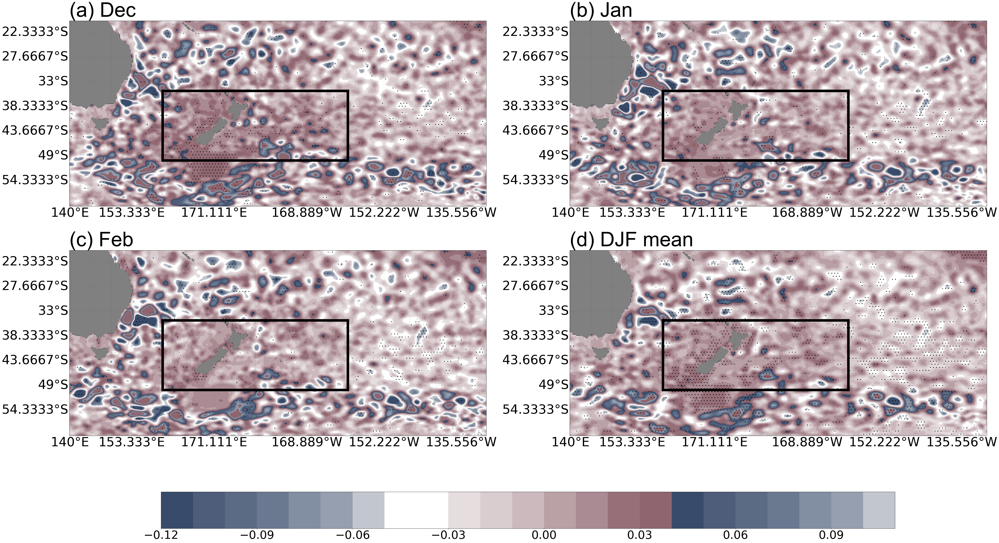

In [45]:
proj = ccrs.PlateCarree(central_longitude=180)
fig,ax=plt.subplots(2,2,figsize=(65,40),subplot_kw={'projection': proj})

#添加框线
start_point = (160, -50)
RE=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE1=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE2=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25
RE3=Rectangle(start_point,200-160,-35+50,linewidth=2,linestyle='-' ,zorder=2,\
              edgecolor='black',facecolor='none', transform=ccrs.PlateCarree()) #25表示纬度间隔25

for i in range(0,2,1):
    for j in range(0,2,1):
        #ax[i][j].contourf(Lon,Lat, cmap='Oranges_r')
        gl = ax[i][j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.2, color='k', alpha=0.5, linestyle='--')
        gl.xlabels_top = False ##关闭上侧坐标显示 projection=ccrs.PlateCarree(central_longitude=180)
        gl.ylabels_right = False ##关闭右侧坐标显示
        gl.xformatter = LONGITUDE_FORMATTER ##坐标刻度转换为经纬度样式
        gl.yformatter = LATITUDE_FORMATTER
        ax[i][j].coastlines()##绘制默认海岸线
        ax[i][j].add_feature(cfeature.LAND,color='grey')####添加陆地######
        ax[i][j].add_feature(cfeature.COASTLINE,lw=0.25)#####添加海岸线#########
        
        #ax[i][j].set_xticks(np.linspace(-20,21,10))
        gl.xlabel_style = {'size': 50, "color": 'k'}     
        gl.ylabel_style = {'size': 50, "color": 'k'}
        gl.xlocator = mticker.FixedLocator(np.concatenate([np.linspace(140,180,10),np.linspace(-180,-130,10)]))
        gl.ylocator = mticker.FixedLocator(np.linspace(-65, -17,10))
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER

# colors =['#08366a','#246aae','#394b6a','#75A6CE','#cae1ee','#E9EFF8','#ffffff','#ffffff', '#FFDBB5','#fee289','#febb56','#fe8c3c','#8f666f','#f64227','#d10e21']
#colors=['#08366a','#246aae','#394b6a','#75A6CE','#cae1ee','#DDEBF1','#f2f5f6','#E7B3DA','#F499A9','#e98b6e', '#d25d4d', '#ca4c43', '#b53438', '#ab2733']
colors = ['#394b6a','#4d5d7A','#5b6b83','#6b7990','#828ea2','#969faf','#c2c7cf','#ffffff','#ffffff','#e6dddf','#dacdd0','#ccb9bd','#baa1a6','#aa8a93','#976f79','#8f666f']


# 创建颜色映射
# cmap = ListedColormap(colors)
# # 设置颜色映射范围
# vmin, vmax = -0.28, 0.28
# 创建颜色映射
#levels = np.linspace(vmin, vmax, 15)
# levels=[-0.1,  -0.08,-0.06,-0.04,-0.02,-0.01,-0.005,-0.002,0.,0.002,0.005,0.01,0.02,0.04,0.06,0.08,0.1]
# norm = BoundaryNorm(levels, cmap.N)


###HAN###
ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], colors=colors,levels=np.linspace(-0.12,0.11,24),transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], colors=colors,levels=np.linspace(-0.12,0.11,24),transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], colors=colors,levels=np.linspace(-0.12,0.11,24),transform=ccrs.PlateCarree(0))
c=ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,colors=colors,levels=np.linspace(-0.12,0.11,24),transform=ccrs.PlateCarree(0))

ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], colors='#8f666f',levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], colors='#8f666f',levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], colors='#8f666f',levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,colors='#8f666f',levels=[levels[-1],999],transform=ccrs.PlateCarree(0))
ax[0][0].contourf(Lon,Lat,ssha_compose_monthly[2], colors='#394b6a',levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[0][1].contourf(Lon,Lat,ssha_compose_monthly[0], colors='#394b6a',levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[1][0].contourf(Lon,Lat,ssha_compose_monthly[1], colors='#394b6a',levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
ax[1][1].contourf(Lon,Lat,ssha_compose_DJF,colors='#394b6a',levels=[-999,levels[0]],transform=ccrs.PlateCarree(0))
###HAN###


clp=ax[0][0].contourf(Lon,Lat,p_sla12,levels =[0,0.05],hatches=['.'],linewidth=10,zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[0][1].contourf(Lon,Lat,p_sla1,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][0].contourf(Lon,Lat,p_sla2,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)
ax[1][1].contourf(Lon,Lat,p_slaDJF,levels =[0,0.05],hatches=['.'],zorder=1,color='none',transform=ccrs.PlateCarree(0),alpha=0)

ax[0][0].set_title('(a) Dec',fontsize=80,fontname='Arial',loc='left')
ax[0][1].set_title('(b) Jan',fontsize=80,fontname='Arial',loc='left')
ax[1][0].set_title('(c) Feb',fontsize=80,fontname='Arial',loc='left')
ax[1][1].set_title('(d) DJF mean',fontsize=80,fontname='Arial',loc='left')

ax[0][0].add_patch(RE)  #添加矩形框，如果这一句求掉了就没有框显示了
ax[0][1].add_patch(RE1)
ax[1][0].add_patch(RE2)
ax[1][1].add_patch(RE3)


RE.set_linewidth(10)
RE1.set_linewidth(10)
RE2.set_linewidth(10)
RE3.set_linewidth(10)

cb=plt.colorbar(c, ax=ax.ravel().tolist(),orientation='horizontal',shrink=0.8,pad=0.1,extend='max')


font = {'family' : 'serif',
        'color'  : 'darkred',
        'weight' : 'normal',
        'size'   : 40,}
#plt.clabel(d,fontsize=30,colors='black')
#plt.clabel(e,fontsize=30,colors='black')

#plt.clabel(f,fontsize=30,colors='black')
#plt.clabel(g,fontsize=30,colors='black')
#cb.set_label('STD of SSTA',fontdict=font) 
cb.ax.tick_params(labelsize=45)
# 设置colorbar的刻度间隔
#cb.ax.xaxis.set_major_locator(ticker.MultipleLocator(0.04))
plt.show()

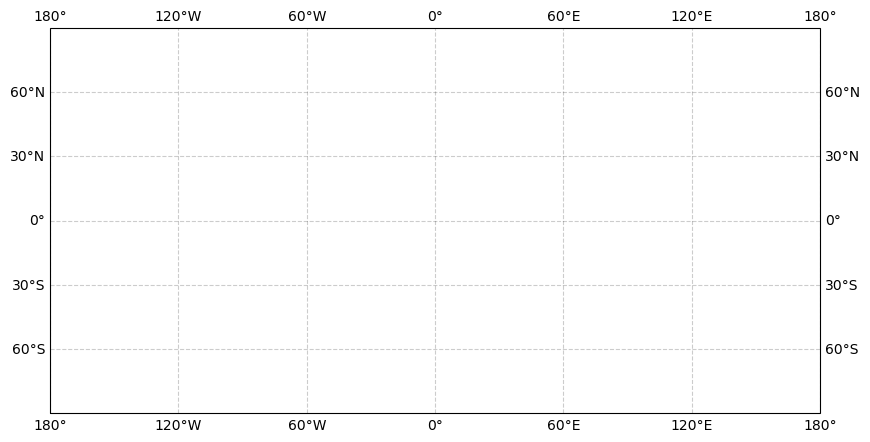

In [40]:
fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())

ax.gridlines(draw_labels=True, color='black', alpha=0.2, linestyle='--')


In [41]:
colors = ['#5fa5cd', '#75b0d3', '#89bbd9', '#9dc7df', '#b0d2e5', '#bfd9ea', '#cde0ef', '#dae7f4', '#e5ecf7', '#eff2fa', '#f8f8fc', '#ffffff', '#fff4fd', '#ffe8ee', '#ffded3', '#ffdbb5', '#ffd39b', '#fdcb81', '#f9c466', '#f6ac50', '#f2933d', '#ee7830', '#e95a29']


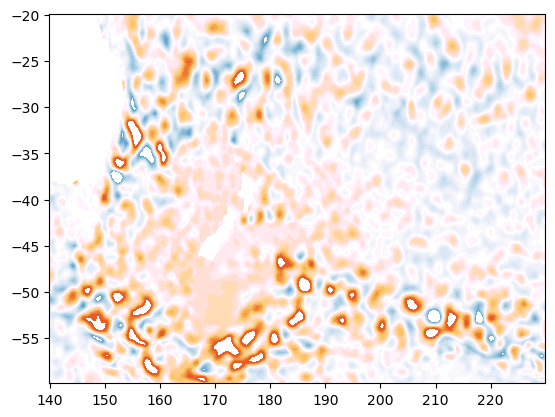

In [42]:
plt.contourf(Lon,Lat,ssha_compose_monthly[2], colors=colors,levels=np.linspace(-0.1,0.1,24))